<a href="https://colab.research.google.com/github/francji1/01RAD/blob/main/code/01RAD_Ex04_HW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01RAD - Homework 04 (team work): The linear algebra of house prices

The file `sarasota_houses_mod.csv` contains 1057 houses sold in one region of the USA with the sale price and a few characteristics:

| column | description |
| --- | --- |
| `price` | sale price in USD |
| `living_area` | interior living area in square feet |
| `bathrooms` | number of bathrooms (can be fractional) |
| `bedrooms` | number of bedrooms |
| `fireplaces` | number of fireplaces |
| `lot_size` | lot size in acres |
| `age` | age of the house in years |
| `fireplace` | indicator whether the house has at least one fireplace |

The homework applies Lecture 4 and Exercise 04 to a real data set: the model matrix, the normal equations as orthogonality, the projection matrices $\mathbf{H}$ and $\mathbf{M}$, reparametrisation, the Frisch–Waugh–Lovell theorem, rank deficiency, and the numerics of least squares (QR, SVD, condition number). Tasks 09 and 10 use Lecture 5 and Exercise 05: the distribution of $\widehat{\boldsymbol{\beta}}$ (Theorems 3.4 and 3.5), dummy variables and interactions. Most tasks can be checked against `statsmodels`; the point is to understand *why* the numbers come out as they do. Write a short answer in a markdown cell after each task.

## Team work
This homework is larger than the previous ones and is solved **in teams of two or three students**. Split the tasks as you like, but every member should be able to explain every answer. At the top of the notebook list the team members and, in one line each, who did what.

## Submission
**Deadline: Sunday 1 November 2026, 23:59** (two weeks, after Exercise 05). Submit through GitHub as before: fork `francji1/01RAD`, save **one notebook per team** into the `HW/` folder as `01RAD_Ex04_HW_<Surname1>_<Surname2>.ipynb` (surnames of all members joined by an underscore, without the brackets, for example `01RAD_Ex04_HW_Novak_Svoboda.ipynb`) and open one pull request to `main`. The pull request should add your one file only; do not modify or delete other files. Python or R, as you prefer.

Useful calls: `patsy.dmatrices`, `np.linalg.qr`, `np.linalg.svd`, `np.linalg.matrix_rank`, `np.linalg.cond`, `scipy.linalg.solve_triangular`, `sm.OLS(y, X).fit()` and `.fit(method='qr')`, `model.df_model`, `model.scale`, `model.get_influence().hat_matrix_diag`.

**Team members**
- Chmela Martin
- Sedláček Jiří

We worked on all tasks together.

## Data

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.linalg as sla
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from patsy import dmatrices

sns.set_theme(style='whitegrid', palette='deep')

url_houses = 'https://raw.githubusercontent.com/francji1/01RAD/main/data/sarasota_houses_mod.csv'
houses = pd.read_csv(url_houses)
print(f'Rows: {houses.shape[0]}, columns: {houses.shape[1]}')
houses.describe().T

Rows: 1057, columns: 8


,count,mean,std,min,25%,50%,75%,max
price,1055.0,167687.885308,77067.890275,16858.0,112276.50,152112.00,206496.00,599701.0
living_area,1057.0,1819.497635,662.941385,672.0,1342.00,1675.00,2223.00,5228.0
bathrooms,1057.0,1.928571,0.650144,1.0,1.50,2.00,2.50,4.5
bedrooms,1057.0,3.184484,0.740486,1.0,3.00,3.00,4.00,5.0
fireplaces,1057.0,0.624409,0.550387,0.0,0.00,1.00,1.00,4.0
lot_size,1048.0,0.570048,0.766297,0.0,0.21,0.39,0.61,9.0
age,1057.0,28.089877,34.928017,0.0,6.00,18.00,34.00,247.0


## Task 01 - Data and the model matrix
Check the missing values and remove the houses with a missing `price` (the column `lot_size` is not used in this homework, so its missing values do not matter). For the model

`price ~ living_area + bathrooms + bedrooms + age + fireplace`

build the model matrix $\mathbf{X}$ once by hand with numpy and once with `dmatrices`, and check that they agree. State $n$, $m+1$, the rank $h(\mathbf{X})$, and what the column for `fireplace` contains.

In [3]:
# your solution
print(houses.isna().sum())
houses = houses.dropna(subset=['price']).reset_index(drop=True)
n = houses.shape[0]

# by hand
y = houses['price'].to_numpy(dtype=float)
X = np.column_stack([np.ones(n), houses['living_area'], houses['bathrooms'],
                     houses['bedrooms'], houses['age'], houses['fireplace'].astype(float)])
names = ['Intercept', 'living_area', 'bathrooms', 'bedrooms', 'age', 'fireplace']

# with patsy (it puts fireplace[T.True] right after the intercept)
y_df, X_df = dmatrices('price ~ living_area + bathrooms + bedrooms + age + fireplace',
                       data=houses, return_type='dataframe')
print(X_df.columns.tolist())
X_patsy = X_df[['Intercept', 'living_area', 'bathrooms', 'bedrooms', 'age', 'fireplace[T.True]']].to_numpy()
print('X by hand == X from dmatrices:', np.allclose(X, X_patsy))

p = X.shape[1]
print(f'n = {n}, m + 1 = {p}, rank h(X) = {np.linalg.matrix_rank(X)}')
print(pd.Series(X[:, 5]).value_counts())

price          2
living_area    0
bathrooms      0
bedrooms       0
fireplaces     0
lot_size       9
age            0
fireplace      0
dtype: int64
['Intercept', 'fireplace[T.True]', 'living_area', 'bathrooms', 'bedrooms', 'age']
X by hand == X from dmatrices: True
n = 1055, m + 1 = 6, rank h(X) = 6
1.0    627
0.0    428
Name: count, dtype: int64


`price` is missing for 2 houses (and `lot_size` for 9, which we do not use), so after removing them $n = 1055$. Both model matrices are the same, patsy only puts `fireplace[T.True]` right after the intercept. $m + 1 = 6$ and $h(\mathbf{X}) = 6$, so $\mathbf{X}$ has full column rank. The column `fireplace` is a dummy variable: 1 if the house has a fireplace (627 houses), 0 if not (428 houses).

## Task 02 - Your own least squares
Write a function `my_ols(X, y)` that uses **only** the QR decomposition (`np.linalg.qr` and a triangular solver, no inverse, no `lstsq`) and returns $\widehat{\boldsymbol{\beta}}$, $\widehat{\mathbf{y}}$, $\widehat{\mathbf{e}}$, $s_n^2$ and the leverages $h_{ii}$. Hint: $\mathbf{H} = \mathbf{Q}\mathbf{Q}^T$, so $h_{ii}$ is the squared norm of the $i$-th row of $\mathbf{Q}$; do not build the $n \times n$ matrix.

Apply it to the model of Task 01 and compare $\widehat{\boldsymbol{\beta}}$, $s_n^2$ (`model.scale`), $R^2$ and $h_{ii}$ (`hat_matrix_diag`) with `statsmodels`. Verify numerically $\mathbf{X}^T\widehat{\mathbf{e}} = \mathbf{0}$, $\sum_i h_{ii} = m+1$, $\|\mathbf{y}\|^2 = \|\widehat{\mathbf{y}}\|^2 + \|\widehat{\mathbf{e}}\|^2$ and $R^2 = \mathrm{corr}^2(\mathbf{y}, \widehat{\mathbf{y}})$.

In [4]:
# your solution
def my_ols(X, y):
    n, p = X.shape
    Q, R = np.linalg.qr(X)                      # X = QR
    beta = sla.solve_triangular(R, Q.T @ y)     # R beta = Q^T y
    y_hat = Q @ (Q.T @ y)                       # H y = Q Q^T y
    e_hat = y - y_hat
    s2 = e_hat @ e_hat / (n - p)
    h = np.sum(Q ** 2, axis=1)                  # h_ii = squared norm of the i-th row of Q
    return beta, y_hat, e_hat, s2, h

beta_hat, y_hat, e_hat, s2, h = my_ols(X, y)
model1 = sm.OLS(y, X).fit()
R2 = 1 - np.sum(e_hat ** 2) / np.sum((y - y.mean()) ** 2)

print(pd.DataFrame({'my_ols': beta_hat, 'statsmodels': model1.params}, index=names))
print(f's_n^2: {s2:.6e} vs {model1.scale:.6e}')
print(f'R^2:   {R2:.6f} vs {model1.rsquared:.6f}')
print(f'max |h_ii - hat_matrix_diag| = {np.abs(h - model1.get_influence().hat_matrix_diag).max():.2e}')

print('X^T e =', X.T @ e_hat)
print(f'sum h_ii = {h.sum():.6f}')
print(f'||y||^2 = {y @ y:.6e},  ||y_hat||^2 + ||e||^2 = {y_hat @ y_hat + e_hat @ e_hat:.6e}')
print(f'R^2 = {R2:.6f},  corr^2(y, y_hat) = {np.corrcoef(y, y_hat)[0, 1] ** 2:.6f}')

                   my_ols   statsmodels
Intercept    15313.400534  15313.400534
living_area     74.840807     74.840807
bathrooms    18945.193811  18945.193811
bedrooms     -6582.792908  -6582.792908
age           -141.106232   -141.106232
fireplace     7889.161957   7889.161957
s_n^2: 2.367793e+09 vs 2.367793e+09
R^2:   0.603237 vs 0.603237
max |h_ii - hat_matrix_diag| = 1.21e-15
X^T e = [-1.48284016e-07 -2.68720090e-04 -2.83325789e-07 -4.80446033e-07
 -4.49214713e-06 -9.14442353e-08]
sum h_ii = 6.000000
||y||^2 = 3.592597e+13,  ||y_hat||^2 + ||e||^2 = 3.592597e+13
R^2 = 0.603237,  corr^2(y, y_hat) = 0.603237


`my_ols` gives the same $\widehat{\boldsymbol{\beta}}$, $s_n^2 = 2.368 \cdot 10^9$, $R^2 = 0.6032$ and $h_{ii}$ as `statsmodels` (differences only from rounding). $\mathbf{X}^T\widehat{\mathbf{e}}$ is zero up to rounding (the residuals are orthogonal to the columns of $\mathbf{X}$), $\sum_i h_{ii} = 6 = m + 1$ (the trace of $\mathbf{H}$), $\|\mathbf{y}\|^2 = \|\widehat{\mathbf{y}}\|^2 + \|\widehat{\mathbf{e}}\|^2$ (Pythagoras, because $\widehat{\mathbf{y}} \perp \widehat{\mathbf{e}}$) and $R^2 = \mathrm{corr}^2(\mathbf{y}, \widehat{\mathbf{y}}) = 0.6032$.

## Task 03 - Units and reparametrisation
We now want the price in **thousands of USD**, the living area in **square metres** ($1\ \mathrm{ft}^2 = 0.09290304\ \mathrm{m}^2$) and the age **centred** at its mean.

1. Show that the new model matrix is $\widetilde{\mathbf{X}} = \mathbf{X}\mathbf{A}$ for a regular matrix $\mathbf{A}$ and write $\mathbf{A}$ explicitly. With $\widetilde{\mathbf{y}} = c\,\mathbf{y}$, derive $\widetilde{\boldsymbol{\beta}} = c\,\mathbf{A}^{-1}\widehat{\boldsymbol{\beta}}$ from the normal equations.
2. **Before fitting**, compute the new coefficients from the old ones with this formula. Then fit the new model and compare.
3. Which of the following change and how: $\widehat{\mathbf{y}}$, $\widehat{\mathbf{e}}$, $s_n$, $R^2$, $h_{ii}$, $\kappa(\mathbf{X})$? Explain with $\mathbf{H}$.
4. Interpret the intercept of the new model in one sentence. Why is the intercept of the original model hard to interpret?

In [5]:
# your solution
c = 1 / 1000
age_mean = houses['age'].mean()
A = np.eye(p)
A[1, 1] = 0.09290304          # ft^2 -> m^2
A[0, 4] = -age_mean           # age - mean(age) * 1
print(A)

# before fitting
beta_pred = c * np.linalg.solve(A, beta_hat)

# new model
X_new = X @ A
y_new = c * y
model3 = sm.OLS(y_new, X_new).fit()
print(pd.DataFrame({'old': beta_hat, 'c A^-1 beta': beta_pred, 'new fit': model3.params}, index=names))

_, y_hat3, e_hat3, s2_3, h3 = my_ols(X_new, y_new)
print('y_hat_new = c * y_hat:', np.allclose(y_hat3, c * y_hat))
print('e_new = c * e:', np.allclose(e_hat3, c * e_hat))
print(f's_n: {np.sqrt(s2):.2f} -> {np.sqrt(s2_3):.4f}')
print(f'R^2: {model1.rsquared:.6f} -> {model3.rsquared:.6f}')
print('h_ii unchanged:', np.allclose(h, h3))
print(f'kappa: {np.linalg.cond(X):.1f} -> {np.linalg.cond(X_new):.1f}')

[[  1.           0.           0.           0.         -28.11848341
    0.        ]
 [  0.           0.09290304   0.           0.           0.
    0.        ]
 [  0.           0.           1.           0.           0.
    0.        ]
 [  0.           0.           0.           1.           0.
    0.        ]
 [  0.           0.           0.           0.           1.
    0.        ]
 [  0.           0.           0.           0.           0.
    1.        ]]
                      old  c A^-1 beta    new fit
Intercept    15313.400534    11.345707  11.345707
living_area     74.840807     0.805580   0.805580
bathrooms    18945.193811    18.945194  18.945194
bedrooms     -6582.792908    -6.582793  -6.582793
age           -141.106232    -0.141106  -0.141106
fireplace     7889.161957     7.889162   7.889162
y_hat_new = c * y_hat: True
e_new = c * e: True
s_n: 48659.97 -> 48.6600
R^2: 0.603237 -> 0.603237
h_ii unchanged: True
kappa: 9880.9 -> 879.7


**1.** Every new column is a linear combination of the old ones: living area in $m^2$ $= 0.09290304\,\mathbf{x}_{living}$ and the centred age $= \mathbf{x}_{age} - \overline{age}\,\mathbf{1}$. So $\widetilde{\mathbf{X}} = \mathbf{X}\mathbf{A}$, where $\mathbf{A}$ is the identity matrix except $A_{11} = 0.09290304$ and $A_{04} = -\overline{age} = -28.12$ (indices from 0, as printed above). $\mathbf{A}$ is upper triangular with a non-zero diagonal, so it is regular. From the normal equations of the new model:
$$\mathbf{A}^T\mathbf{X}^T\mathbf{X}\mathbf{A}\widetilde{\boldsymbol\beta} = c\,\mathbf{A}^T\mathbf{X}^T\mathbf{y} \;\Rightarrow\; \mathbf{X}^T\mathbf{X}(\mathbf{A}\widetilde{\boldsymbol\beta}) = c\,\mathbf{X}^T\mathbf{y} \;\Rightarrow\; \mathbf{A}\widetilde{\boldsymbol\beta} = c\,\widehat{\boldsymbol\beta} \;\Rightarrow\; \widetilde{\boldsymbol\beta} = c\,\mathbf{A}^{-1}\widehat{\boldsymbol\beta}.$$

**2.** The coefficients computed from the formula are the same as those of the fitted new model.

**3.** $\widehat{\mathbf{y}}$, $\widehat{\mathbf{e}}$ and $s_n$ are multiplied by $c$ ($s_n$: 48 660 USD → 48.66 thousand USD). $R^2$ and $h_{ii}$ do not change, because $\mathbf{A}$ is regular, so $\mathcal{M}(\mathbf{X}\mathbf{A}) = \mathcal{M}(\mathbf{X})$ and $\mathbf{H}$ is the same; then $\mathbf{H}(c\mathbf{y}) = c\,\widehat{\mathbf{y}}$. $\kappa(\mathbf{X})$ changes (9881 → 880), because it depends on the scale of the columns.

**4.** The new intercept (11.3 thousand USD) is the predicted price of a house of average age without a fireplace and with zero living area, bathrooms and bedrooms. The original intercept is for a new house (age 0) with all other variables equal to zero, which is far outside the data, so it has no practical meaning.

## Task 04 - The bedroom paradox
Fit the simple regression `price ~ bedrooms` and compare its slope with the coefficient of `bedrooms` in the model of Task 01. The signs differ.

1. Verify the Frisch–Waugh–Lovell theorem for `bedrooms`: compute $\mathbf{M}_{-j}\mathbf{x}_j$ and $\mathbf{M}_{-j}\mathbf{y}$ (residuals of the regressions of `bedrooms` and of `price` on the other columns) and show that the slope of one on the other equals the multiple regression coefficient.
2. Draw both scatter plots (raw and cleaned) with their lines.
3. How much of the variability of `bedrooms` is explained by the other regressors ($R^2$ of the auxiliary regression)?
4. Explain the paradox in plain words for a real estate agent: what does the negative coefficient say about two houses that differ in the number of bedrooms but **not** in the other variables?

simple regression: 48383.40,  multiple regression: -6582.79
FWL slope: -6582.792908,  coefficient: -6582.792908


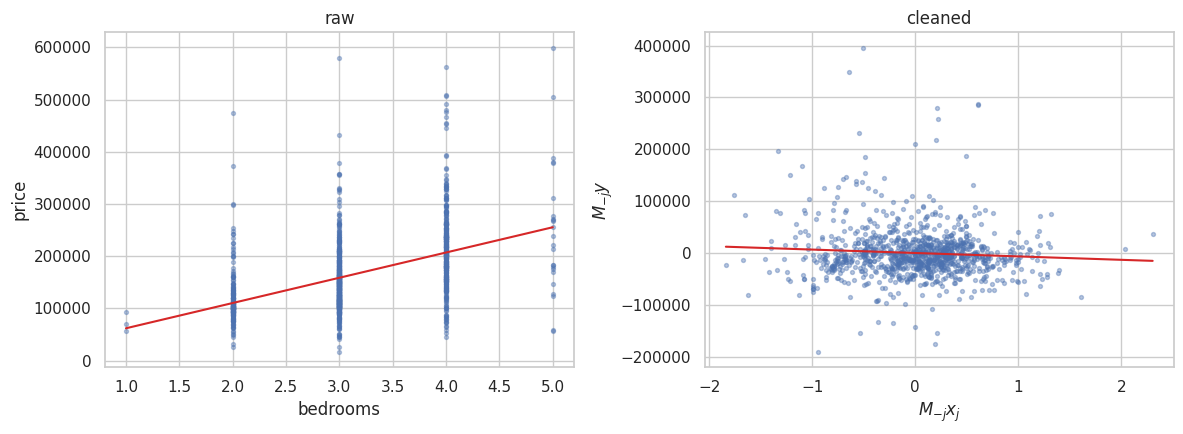

R^2(bedrooms ~ others) = 0.457


In [6]:
# your solution
simple = smf.ols('price ~ bedrooms', data=houses).fit()
print(f"simple regression: {simple.params['bedrooms']:.2f},  multiple regression: {beta_hat[3]:.2f}")

# 1. FWL
X_other = X[:, [0, 1, 2, 4, 5]]                    # all columns except bedrooms
_, bed_fit, x_res, _, _ = my_ols(X_other, X[:, 3])  # M_{-j} x_j
_, _, y_res, _, _ = my_ols(X_other, y)              # M_{-j} y
fwl = (x_res @ y_res) / (x_res @ x_res)
print(f'FWL slope: {fwl:.6f},  coefficient: {beta_hat[3]:.6f}')

# 2. plots
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(houses['bedrooms'], y, s=8, alpha=0.4)
g = np.linspace(1, 5, 50)
axes[0].plot(g, simple.params['Intercept'] + simple.params['bedrooms'] * g, color='tab:red')
axes[0].set_xlabel('bedrooms'); axes[0].set_ylabel('price'); axes[0].set_title('raw')
axes[1].scatter(x_res, y_res, s=8, alpha=0.4)
g = np.linspace(x_res.min(), x_res.max(), 50)
axes[1].plot(g, fwl * g, color='tab:red')
axes[1].set_xlabel('$M_{-j}x_j$'); axes[1].set_ylabel('$M_{-j}y$'); axes[1].set_title('cleaned')
plt.tight_layout(); plt.show()

# 3. R^2 of the auxiliary regression
x_bed = X[:, 3]
print(f'R^2(bedrooms ~ others) = {1 - np.sum(x_res ** 2) / np.sum((x_bed - x_bed.mean()) ** 2):.3f}')

The simple regression gives +48 383 USD per bedroom, the multiple regression −6 583 USD.

**1.** The slope of $\mathbf{M}_{-j}\mathbf{y}$ on $\mathbf{M}_{-j}\mathbf{x}_j$ is −6582.79, the same as the coefficient of `bedrooms` in Task 01.

**2.** In the raw plot the price grows with the number of bedrooms, in the cleaned plot the line slightly falls.

**3.** $R^2 = 0.457$: almost half of the variability of `bedrooms` is explained by the other regressors (mostly by the living area).

**4.** Houses with more bedrooms are usually bigger, and that is why they are more expensive. The negative coefficient compares two houses with the same living area, bathrooms, age and fireplace: the one with an extra bedroom has the same area divided into more, smaller rooms, and it sells on average for about 6 600 USD less.

## Task 05 - Dummy variables and the trap
1. Add the column `no_fireplace = 1 - fireplace` to the model matrix of Task 01 (keeping the intercept). What is the rank? Fit the model with `sm.OLS(y, X).fit()` and with your `my_ols`. Which coefficients are identified (i.e. are the same for every solution of the normal equations)? Express them through the output. What would R's `lm` report?
2. Now remove the intercept and keep **both** dummies. What is the rank now? Show that this model has exactly the same fitted values as the model of Task 01 and explain why with the column space $\mathcal{M}(\mathbf{X})$. How are the coefficients of the two parametrisations related?
3. Compare the `R-squared` reported by `statsmodels` for the model in 2. with Task 01. In Exercise 03 the model through the origin reported the uncentred $R^2 = \sum_i \widehat{y}_i^2 / \sum_i y_i^2$. Is that the case here? Explain why not (hint: is the vector $\mathbf{1}$ in $\mathcal{M}(\mathbf{X})$?) and what really decides whether a model "has an intercept".

In [7]:
# your solution
# 1. intercept + fireplace + no_fireplace
no_fire = 1 - X[:, 5]
X5 = np.column_stack([X, no_fire])
names5 = names + ['no_fireplace']
print('columns:', X5.shape[1], ' rank:', np.linalg.matrix_rank(X5))

fit5 = sm.OLS(y, X5).fit()
b5_my = my_ols(X5, y)[0]
print(pd.DataFrame({'statsmodels (pinv)': fit5.params, 'my_ols': b5_my}, index=names5))

b = fit5.params
print('b0 + b_no_fire   =', b[0] + b[6])
print('b0 + b_fire      =', b[0] + b[5])
print('b_fire - b_no_fire =', b[5] - b[6])

# 2. no intercept, both dummies
X5b = np.column_stack([X[:, 1:], no_fire])
print('columns:', X5b.shape[1], ' rank:', np.linalg.matrix_rank(X5b))
fit5b = sm.OLS(y, X5b).fit()
print('same fitted values as Task 01:', np.allclose(fit5b.fittedvalues, y_hat))
print(pd.Series(fit5b.params, index=names[1:] + ['no_fireplace']))

# 3. R^2
print(f'R^2 statsmodels: {fit5b.rsquared:.4f},  Task 01: {model1.rsquared:.4f}')
print(f'uncentred R^2: {np.sum(fit5b.fittedvalues ** 2) / np.sum(y ** 2):.4f}')

columns: 7  rank: 6
              statsmodels (pinv)        my_ols
Intercept           12838.654342 -1.657483e+16
living_area            74.840807  7.485273e+01
bathrooms           18945.193811  1.894191e+04
bedrooms            -6582.792908 -6.585210e+03
age                  -141.106232 -1.410151e+02
fireplace           10363.908149  1.657483e+16
no_fireplace         2474.746192  1.657483e+16
b0 + b_no_fire   = 15313.400533878388
b0 + b_fire      = 23202.562490775446
b_fire - b_no_fire = 7889.161956897058
columns: 6  rank: 6
same fitted values as Task 01: True
living_area        74.840807
bathrooms       18945.193811
bedrooms        -6582.792908
age              -141.106232
fireplace       23202.562491
no_fireplace    15313.400534
dtype: float64
R^2 statsmodels: 0.6032,  Task 01: 0.6032
uncentred R^2: 0.9309


/tmp/ipykernel_7566/2454228338.py:8: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  fit5 = sm.OLS(y, X5).fit()


**1.** The rank is 6 with 7 columns, because `fireplace` + `no_fireplace` = $\mathbf{1}$, so the normal equations have infinitely many solutions. `statsmodels` (pinv) returns the minimum-norm solution, `my_ols` fails: $\mathbf{R}$ is singular and the coefficients come out of order $10^{16}$. Identified are the coefficients of `living_area`, `bathrooms`, `bedrooms` and `age`, and the combinations $\beta_0 + \beta_{no\_fire} = 15\,313$, $\beta_0 + \beta_{fire} = 23\,203$ and $\beta_{fire} - \beta_{no\_fire} = 7\,889$, which are the same as in Task 01. R's `lm` would report `NA` for `no_fireplace` and the coefficients of Task 01 for the rest.

**2.** The rank is 6 with 6 columns. The fitted values are the same as in Task 01, because $\mathbf{1} = $ `fireplace` + `no_fireplace`, so both matrices have the same column space $\mathcal{M}(\mathbf{X})$ and the same projection $\mathbf{H}$. The coefficient of `no_fireplace` is $\beta_0$ of Task 01 (15 313), the coefficient of `fireplace` is $\beta_0 + \beta_{fire}$ (23 203), the other coefficients are the same.

**3.** `statsmodels` reports $R^2 = 0.6032$ as in Task 01, not the uncentred $R^2 = 0.931$. The reason is that $\mathbf{1} \in \mathcal{M}(\mathbf{X})$, so the model in fact has an intercept, and `statsmodels` detects it. What decides whether a model has an intercept is not a column of ones, but whether $\mathbf{1}$ lies in $\mathcal{M}(\mathbf{X})$.

## Task 06 - Leverage as a data check
Plot the leverages $h_{ii}$ of the model of Task 01 against the observation index and list the ten houses with the largest $h_{ii}$. Compare with the mean leverage $(m+1)/n$.

1. What do the houses with the largest leverage have in common? Look at the variable `age` in particular: how many houses are older than 100 and older than 200 years, and how do they differ from the rest in the other variables? Are such values plausible, and what would you check or ask before using them?
2. Refit the model without the houses with `age` above 150 years and compare the coefficients, in particular the coefficient of `age`. Does the decision matter?
3. Leverage depends only on $\mathbf{X}$. Why is it nevertheless a good tool for finding errors in the data, before the response is even used?

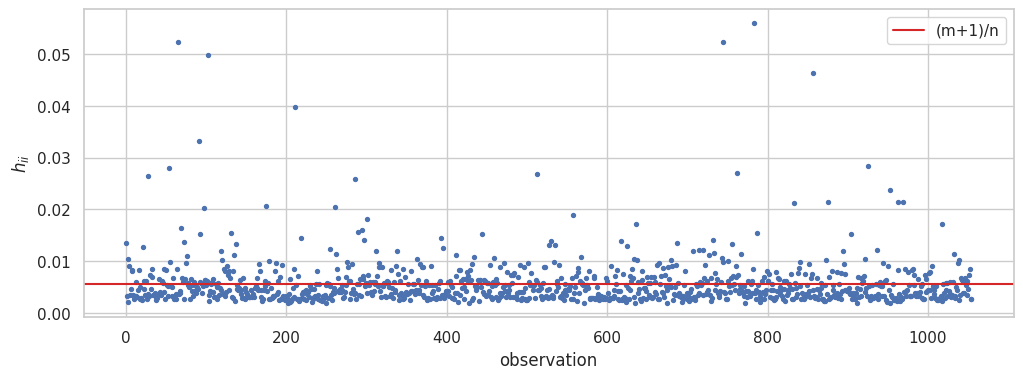

mean leverage (m+1)/n = 0.0057
        price  living_area  bathrooms  bedrooms  age  fireplace      h_ii
783   88092.0         3944        1.0         4  185       True  0.055933
745  599701.0         5114        4.5         5  131       True  0.052303
65   226742.0         1989        2.0         3  247       True  0.052240
102   59003.0         3285        2.0         5  233      False  0.049844
857   75975.0         1300        2.0         3  227       True  0.046357
211  562546.0         5228        4.0         4   14       True  0.039726
91   185318.0         1500        1.5         4  208       True  0.033288
925  139627.0         1980        1.0         4  205      False  0.028452
54   157513.0         2164        2.0         3  183       True  0.028049
762  139104.0         1760        3.0         4  135      False  0.027108
older than 100: 71  older than 200: 5
                age <= 100  100 < age <= 200  age > 200
price        171443.604675     113993.136364   137333.0
livin

In [8]:
# your solution
plt.figure(figsize=(12, 4))
plt.scatter(np.arange(n), h, s=8)
plt.axhline(p / n, color='tab:red', label='(m+1)/n')
plt.xlabel('observation'); plt.ylabel('$h_{ii}$'); plt.legend()
plt.show()

top = np.argsort(h)[::-1][:10]
print(f'mean leverage (m+1)/n = {p / n:.4f}')
print(houses.loc[top, ['price', 'living_area', 'bathrooms', 'bedrooms', 'age', 'fireplace']].assign(h_ii=h[top]))

# 1. age
print('older than 100:', (houses['age'] > 100).sum(), ' older than 200:', (houses['age'] > 200).sum())
cols = ['price', 'living_area', 'bathrooms', 'bedrooms', 'fireplace']
print(pd.DataFrame({'age <= 100': houses.loc[houses['age'] <= 100, cols].mean(),
                    '100 < age <= 200': houses.loc[(houses['age'] > 100) & (houses['age'] <= 200), cols].mean(),
                    'age > 200': houses.loc[houses['age'] > 200, cols].mean()}))

# 2. without age > 150
keep = (houses['age'] <= 150).to_numpy()
model6 = sm.OLS(y[keep], X[keep]).fit()
print('removed:', (~keep).sum())
print(pd.DataFrame({'all': model1.params, 'age <= 150': model6.params,
                    'se all': model1.bse, 'se age <= 150': model6.bse}, index=names))

The mean leverage is $(m+1)/n = 0.0057$; the ten largest $h_{ii}$ are 0.027–0.056, i.e. 5 to 10 times more.

**1.** Nine of the ten houses are older than 100 years (131–247 years), the tenth is the largest house in the data (5228 ${ft}^2$). 71 houses are older than 100 years and 5 older than 200 years. The houses aged 100–200 years are cheaper, smaller, have fewer bathrooms and fewer fireplaces than the rest. A house older than 200 years is not very plausible; I would ask how `age` was measured and whether these values are not typos.

**2.** Without the 15 houses older than 150 years the coefficient of `age` changes from −141 to −57 USD per year and is no longer significant (SE 60). The other coefficients change much less. So the decision matters for the effect of age.

**3.** $h_{ii}$ depends only on $\mathbf{X}$ and measures how far the regressors of a house are from the centre of the data. Errors in the data usually give extreme or unusual combinations of values, so they show up as large leverage even before we use the response.

## Task 07 - When the default fails: polynomials in the living area
Fit polynomial models `price` $= \beta_0 + \beta_1 a + \beta_2 a^2 + \dots + \beta_d a^d + e$ in the living area $a$ (square feet, raw) for degrees $d = 1, \dots, 6$, building the columns $a^k$ yourself (`np.vander`). For each degree record in one table:
- $\kappa(\mathbf{X})$ and `np.linalg.matrix_rank(X)`,
- $R^2$ and `df_model` from `sm.OLS(y, X).fit()` (default, pseudoinverse),
- $R^2$ from `sm.OLS(y, X).fit(method='qr')` and from your `my_ols`,
- $R^2$ with the standardized variable $(a - \overline{a})/s_a$ instead of $a$.

1. The models are **nested**: the model of degree $d+1$ contains the model of degree $d$. What does that imply for $R^2$ as $d$ grows (think of the projection onto a larger subspace)? Which column of the table violates this, and from which degree on?
2. Explain what the default method does wrong. Hint: compute the singular values of $\mathbf{X}$, compare them with the tolerance used to decide which ones count as zero (`np.linalg.matrix_rank` uses $s_1 \cdot \max(n, p) \cdot \varepsilon_{\text{machine}}$), and look at `df_model`.
3. Why do QR and the standardized version give the correct answer? Which fix would you use in practice?

In [9]:
# your solution
a = houses['living_area'].to_numpy(dtype=float)
z = (a - a.mean()) / a.std()
eps = 2.220446049250313e-16          # machine epsilon for float64

rows = []
for d in range(1, 7):
    Xd = np.vander(a, d + 1, increasing=True)
    Zd = np.vander(z, d + 1, increasing=True)
    fit_pinv = sm.OLS(y, Xd).fit()
    _, yh, _, _, _ = my_ols(Xd, y)
    rows.append({'d': d,
                 'kappa': np.linalg.cond(Xd),
                 'rank': np.linalg.matrix_rank(Xd),
                 'R2 pinv': fit_pinv.rsquared,
                 'df_model': fit_pinv.df_model,
                 'R2 qr': sm.OLS(y, Xd).fit(method='qr').rsquared,
                 'R2 my_ols': 1 - np.sum((y - yh) ** 2) / np.sum((y - y.mean()) ** 2),
                 'R2 standardized': sm.OLS(y, Zd).fit().rsquared})
print(pd.DataFrame(rows).set_index('d'))

# 2. singular values and the tolerance
for d in range(1, 7):
    s = np.linalg.svd(np.vander(a, d + 1, increasing=True), compute_uv=False)
    print(f'd = {d}: tolerance = {s[0] * max(n, d + 1) * eps:.2e}, singular values:', s)

          kappa  rank   R2 pinv  df_model     R2 qr  R2 my_ols  \
d                                                                
1  5.655650e+03     2  0.575660       1.0  0.575660   0.575660   
2  3.198968e+07     3  0.582868       2.0  0.582868   0.582868   
3  1.918004e+11     4  0.583051       3.0  0.583051   0.583051   
4  1.527113e+15     4  0.580213       3.0  0.587821   0.587821   
5  1.024160e+19     4  0.565239       3.0  0.587933   0.587933   
6  1.627291e+23     4  0.511069       3.0  0.587967   0.587967   

   R2 standardized  
d                   
1         0.575660  
2         0.582868  
3         0.583051  
4         0.587821  
5         0.587933  
6         0.587967  
d = 1: tolerance = 1.47e-08, singular values: [6.28634292e+04 1.11151559e+01]
d = 2: tolerance = 3.61e-05, singular values: [1.53956768e+08 2.02412054e+04 4.81270039e+00]
d = 3: tolerance = 1.08e-01, singular values: [4.61292348e+11 4.58730356e+07 8.81539911e+03 2.40506467e+00]
d = 4: tolerance = 3.85e

/tmp/ipykernel_7566/3061857387.py:10: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  fit_pinv = sm.OLS(y, Xd).fit()
/tmp/ipykernel_7566/3061857387.py:10: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  fit_pinv = sm.OLS(y, Xd).fit()
/tmp/ipykernel_7566/3061857387.py:10: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  fit_pinv = sm.OLS(y, Xd).fit()


**1.** The models are nested, so each one is a projection onto a larger subspace than the previous one, and $R^2$ cannot decrease as $d$ grows. The column `R2 pinv` violates this from $d = 4$ on (0.5831 → 0.5802 → 0.5652 → 0.5111).

**2.** $\kappa(\mathbf{X})$ grows from $5.7 \cdot 10^3$ to $1.6 \cdot 10^{23}$. From $d = 4$ the smallest singular values are below the tolerance, so they are treated as zero: `matrix_rank` gives 4 and `df_model` stays 3. The default method (pinv) drops these directions, even though the columns are linearly independent, and projects $\mathbf{y}$ onto a smaller and different subspace. That is why $R^2$ decreases.

**3.** QR does not drop any direction and $\widehat{\mathbf{y}} = \mathbf{Q}\mathbf{Q}^T\mathbf{y}$ is computed accurately even for a badly conditioned $\mathbf{X}$. After standardization $\kappa$ is small, so any method works. In practice I would standardize (centre and scale) the variable before building the powers.

## Task 08 - Singular values and the variance of the estimates
Take the model of Task 01 with all non-intercept columns standardized (including `fireplace`), so that the coefficients are comparable.

1. Compute the SVD $\mathbf{X} = \mathbf{P}\mathbf{S}\mathbf{Q}^T$, the singular values and $\kappa(\mathbf{X})$. Is there a problem with collinearity in this model?
2. `statsmodels` reports the standard errors $\sqrt{s_n^2\,[(\mathbf{X}^T\mathbf{X})^{-1}]_{jj}}$ (Theorem 3.4 will justify this in the next lecture). Using the SVD, write $[(\mathbf{X}^T\mathbf{X})^{-1}]_{jj} = \sum_k q_{jk}^2/s_k^2$ and compute the standard errors from this formula; compare with `model.bse`.
3. For the coefficient of `bedrooms`, compute the share of each term $q_{jk}^2/s_k^2$ in the sum. Which singular direction contributes most? Which variables have large weights in that direction $\mathbf{q}_k$, and how does it relate to Task 04?

In [10]:
# your solution
Xs = X.copy()
Xs[:, 1:] = (X[:, 1:] - X[:, 1:].mean(axis=0)) / X[:, 1:].std(axis=0)
model8 = sm.OLS(y, Xs).fit()

# 1. SVD
P, s, Qt = np.linalg.svd(Xs, full_matrices=False)
Qm = Qt.T
print('singular values:', s)
print(f'kappa = {s[0] / s[-1]:.3f}')

# 2. standard errors from the SVD
v = np.sum(Qm ** 2 / s ** 2, axis=1)            # [(X^T X)^{-1}]_jj = sum_k q_jk^2 / s_k^2
print(pd.DataFrame({'se SVD': np.sqrt(model8.scale * v), 'bse': model8.bse}, index=names))

# 3. bedrooms
terms = Qm[3] ** 2 / s ** 2
print('shares:', terms / terms.sum())
k = np.argmax(terms)
print(f'largest share: k = {k + 1}')
print(pd.Series(Qm[:, k], index=names))

singular values: [53.76548593 32.48076354 32.28298687 26.71364009 19.87399513 15.28028247]
kappa = 3.519
                  se SVD          bse
Intercept    1498.116664  1498.116664
living_area  2601.914788  2601.914788
bathrooms    2398.262740  2398.262740
bedrooms     2033.515327  2033.515327
age          1693.699694  1693.699694
fireplace    1737.643123  1737.643123
shares: [0.03834612 0.         0.14012684 0.05757244 0.59602505 0.16792955]
largest share: k = 5
Intercept     -0.000000
living_area    0.255819
bathrooms      0.596855
bedrooms      -0.641199
age            0.373245
fireplace     -0.166950
dtype: float64


**1.** The singular values are 53.8, 32.5, 32.3, 26.7, 19.9 and 15.3, so $\kappa(\mathbf{X}) = 3.5$. That is small, so there is no problem with collinearity.

**2.** From $\mathbf{X} = \mathbf{P}\mathbf{S}\mathbf{Q}^T$ we get $(\mathbf{X}^T\mathbf{X})^{-1} = \mathbf{Q}\mathbf{S}^{-2}\mathbf{Q}^T$, so $[(\mathbf{X}^T\mathbf{X})^{-1}]_{jj} = \sum_k q_{jk}^2/s_k^2$. The standard errors from this formula are the same as `model.bse`.

**3.** For `bedrooms` the fifth direction ($s_5 = 19.9$) gives 60 % of the sum. In $\mathbf{q}_5$ the large weights are `bedrooms` (−0.64), `bathrooms` (+0.60) and `age` (+0.37): more bedrooms, but fewer bathrooms. The data vary little in this direction (small $s_5$), so the coefficient of `bedrooms` is estimated less precisely. This is the same as in Task 04: the coefficient uses only the part of `bedrooms` that is not explained by the other variables.

## Task 09 - Theorem 3.4 by simulation
Take the model of Task 01 as the truth: the model matrix $\mathbf{X}$ is fixed (the 1055 houses), the true parameters are $\boldsymbol{\beta} = \widehat{\boldsymbol{\beta}}$ and $\sigma = s_n$ from Task 01. Generate at least 2000 new response vectors $\mathbf{y}^* = \mathbf{X}\boldsymbol{\beta} + \mathbf{e}^*$, $\mathbf{e}^* \sim N_n(\mathbf{0}, \sigma^2\mathbf{I}_n)$, and in each replication compute $\widehat{\boldsymbol{\beta}}^*$ and $s_n^{2*}$ (use your `my_ols`).

1. Compare the mean of $\widehat{\boldsymbol{\beta}}^*$ with $\boldsymbol{\beta}$ and the mean of $s_n^{2*}$ with $\sigma^2$ (Theorem 3.4, points 1 and 3).
2. Compare the empirical covariance matrix of $\widehat{\boldsymbol{\beta}}^*$ with $\sigma^2(\mathbf{X}^T\mathbf{X})^{-1}$: the standard deviations of the coefficients and the correlation matrix.
3. The estimates of the coefficients of `bedrooms` and `living_area` are correlated. Which sign does the correlation have, and why? Draw the scatter plot of the two estimates and relate it to the correlation of the regressors and to Task 04.
4. For `bedrooms`, check that $T = (\widehat{\beta}_j^* - \beta_j)/\big(s_n^*\sqrt{[(\mathbf{X}^T\mathbf{X})^{-1}]_{jj}}\big)$ has the $t(n-m-1)$ distribution (Theorem 3.5): histogram with the density, and the share of replications in which the 95 % confidence interval covers the true $\beta_j$.

                true beta  mean of estimates
Intercept    15313.400534       15117.704494
living_area     74.840807          74.845686
bathrooms    18945.193811       18957.314312
bedrooms     -6582.792908       -6544.318505
age           -141.106232        -140.406834
fireplace     7889.161957        7940.129913
sigma^2 = 2.36779e+09,  mean of s_n^2 = 2.36755e+09
               sd theory  sd simulated
Intercept    7322.384487   7187.333207
living_area     3.928547      3.859509
bathrooms    3689.778429   3666.911629
bedrooms     2749.804550   2667.057710
age            48.477711     48.935905
fireplace    3538.811180   3463.602849
theoretical correlation matrix:
             Intercept  living_area  bathrooms  bedrooms    age  fireplace
Intercept        1.000        0.171     -0.362    -0.598 -0.339      0.017
living_area      0.171        1.000     -0.522    -0.475 -0.026     -0.231
bathrooms       -0.362       -0.522      1.000    -0.111  0.360     -0.119
bedrooms        -0.598      

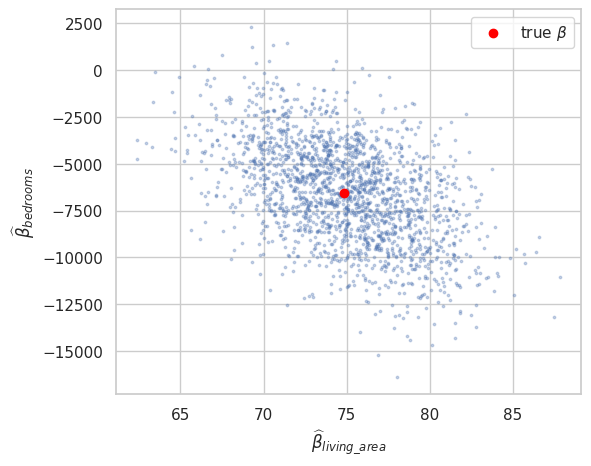

corr of the estimates: -0.479,  corr of the regressors: 0.663


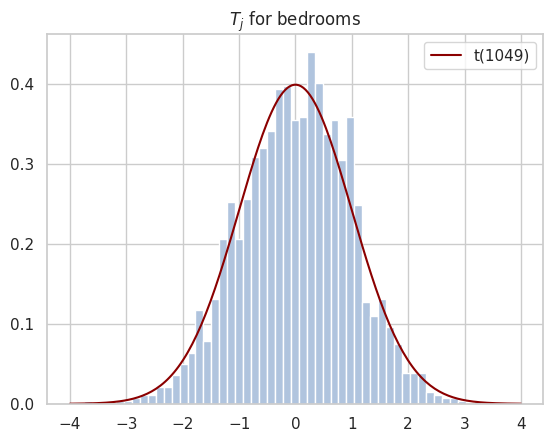

coverage of the 95% CI: 0.9590


In [11]:
# your solution
rng = np.random.default_rng(2026)
B = 2000
beta_true, sigma = beta_hat, np.sqrt(s2)
XtX_inv = np.linalg.inv(X.T @ X)

B_sim = np.zeros((B, p))
S2_sim = np.zeros(B)
for b in range(B):
    y_star = X @ beta_true + sigma * rng.standard_normal(n)
    B_sim[b], _, _, S2_sim[b], _ = my_ols(X, y_star)

# 1.
print(pd.DataFrame({'true beta': beta_true, 'mean of estimates': B_sim.mean(axis=0)}, index=names))
print(f'sigma^2 = {sigma ** 2:.5e},  mean of s_n^2 = {S2_sim.mean():.5e}')

# 2.
cov_theory = sigma ** 2 * XtX_inv
d_th = np.sqrt(np.diag(cov_theory))
print(pd.DataFrame({'sd theory': d_th, 'sd simulated': B_sim.std(axis=0, ddof=1)}, index=names))
print('theoretical correlation matrix:')
print(pd.DataFrame(cov_theory / np.outer(d_th, d_th), index=names, columns=names).round(3))
print('simulated correlation matrix:')
print(pd.DataFrame(np.corrcoef(B_sim, rowvar=False), index=names, columns=names).round(3))

# 3.
plt.figure(figsize=(6, 5))
plt.scatter(B_sim[:, 1], B_sim[:, 3], s=3, alpha=0.3)
plt.scatter(beta_true[1], beta_true[3], color='red', label='true $\\beta$')
plt.xlabel('$\\widehat{\\beta}_{living\\_area}$'); plt.ylabel('$\\widehat{\\beta}_{bedrooms}$'); plt.legend()
plt.show()
print(f'corr of the estimates: {np.corrcoef(B_sim[:, 1], B_sim[:, 3])[0, 1]:.3f},'
      f'  corr of the regressors: {np.corrcoef(X[:, 1], X[:, 3])[0, 1]:.3f}')

# 4.
j = 3
df_t = n - p
T_j = (B_sim[:, j] - beta_true[j]) / np.sqrt(S2_sim * XtX_inv[j, j])
g = np.linspace(-4, 4, 200)
plt.hist(T_j, bins=50, density=True, color='lightsteelblue')
plt.plot(g, stats.t.pdf(g, df_t), color='darkred', label=f't({df_t})')
plt.title('$T_j$ for bedrooms'); plt.legend()
plt.show()
q = stats.t.ppf(0.975, df_t)
print(f'coverage of the 95% CI: {np.mean(np.abs(T_j) <= q):.4f}')

**1.** The means of the estimates are close to the true $\boldsymbol\beta$ (e.g. −6544 vs −6583 for `bedrooms`, the difference is small compared to the standard deviation 2700), and the mean of $s_n^{2*}$ is $2.3676 \cdot 10^9$ vs $\sigma^2 = 2.3678 \cdot 10^9$. So $\widehat{\boldsymbol\beta}$ and $s_n^2$ are unbiased (Theorem 3.4).

**2.** The simulated standard deviations and correlations agree with $\sigma^2(\mathbf{X}^T\mathbf{X})^{-1}$ up to the simulation error (sd within 3 %, correlations within about 0.05).

**3.** The correlation of the estimates of `living_area` and `bedrooms` is negative (−0.48), although the regressors are positively correlated (0.66). Both variables describe the size of the house, so when one coefficient comes out higher, the other comes out lower. This is the same effect as in Task 04.

**4.** The histogram of $T$ follows the $t(1049)$ density and the 95 % confidence interval covered the true $\beta_j$ in 95.9 % of the replications, which agrees with Theorem 3.5.

## Task 10 - Fireplace: interaction and separate regressions
Fit the model `price ~ living_area * fireplace` (R: `lm(price ~ living_area * fireplace)`).

1. Write the model matrix for this formula: which four columns does it have? Write the two regression lines (houses without and with a fireplace) in terms of the four coefficients and interpret each coefficient in one sentence, including its units.
2. Test whether the price per square foot is the same for houses with and without a fireplace (the $t$-test of the interaction term). State the hypotheses, the statistic, the degrees of freedom and the conclusion. Draw the data with the two fitted lines.
3. Now fit two separate simple regressions `price ~ living_area`, one for the houses with and one for the houses without a fireplace. Compare the coefficients with the lines from 1.: what is equal and why? (Think of the column space of the interaction model and of a model matrix that is block diagonal after reordering the rows.)
4. Compare $s_n$ and the standard errors of the slopes in the interaction model and in the two separate models. Which assumption about $\sigma^2$ makes the difference? Which approach would you prefer here, and what would you check to decide?

                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept         4.218e+04   7915.205      5.329      0.000    2.66e+04    5.77e+04
living_area         59.7433      5.257     11.364      0.000      49.428      70.059
fire             -3.762e+04   1.03e+04     -3.660      0.000   -5.78e+04   -1.74e+04
living_area:fire    31.7265      6.056      5.239      0.000      19.844      43.609
without fireplace: 42179.7 + 59.743 * living_area
with fireplace:    4564.3 + 91.470 * living_area
t = 5.239, df = 1051, p = 1.95e-07


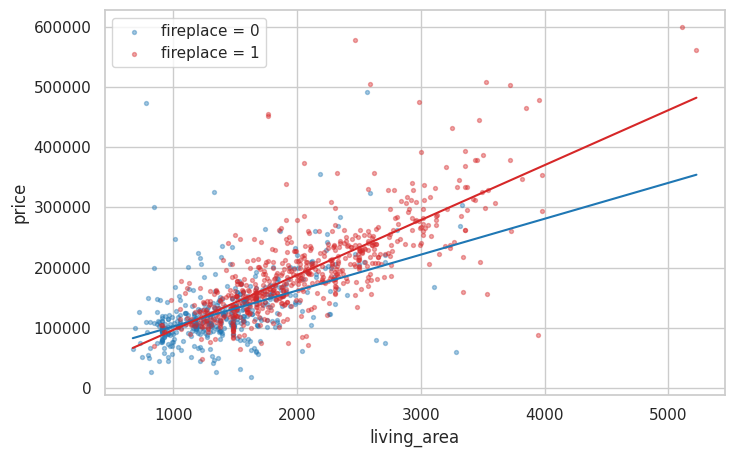

without fireplace: [42179.74581306    59.74330387]
with fireplace:    [4564.29913463   91.4698052 ]
s_n: interaction 49321, without 48147, with 50106
se of the slope without fireplace: 5.257 vs 5.132
se of the slope with fireplace:    3.006 vs 3.054


In [12]:
# your solution
houses['fire'] = houses['fireplace'].astype(int)
model10 = smf.ols('price ~ living_area * fire', data=houses).fit()
print(model10.summary().tables[1])

# 1.
bi = model10.params
print(f"without fireplace: {bi['Intercept']:.1f} + {bi['living_area']:.3f} * living_area")
print(f"with fireplace:    {bi['Intercept'] + bi['fire']:.1f} + {bi['living_area'] + bi['living_area:fire']:.3f} * living_area")

# 2.
print(f"t = {model10.tvalues['living_area:fire']:.3f}, df = {model10.df_resid:.0f}, p = {model10.pvalues['living_area:fire']:.2e}")
g = np.linspace(houses['living_area'].min(), houses['living_area'].max(), 100)
plt.figure(figsize=(8, 5))
for f, col in [(0, 'tab:blue'), (1, 'tab:red')]:
    sub = houses[houses['fire'] == f]
    plt.scatter(sub['living_area'], sub['price'], s=8, alpha=0.4, color=col, label=f'fireplace = {f}')
    plt.plot(g, model10.predict(pd.DataFrame({'living_area': g, 'fire': f})), color=col)
plt.xlabel('living_area'); plt.ylabel('price'); plt.legend()
plt.show()

# 3.
fit0 = smf.ols('price ~ living_area', data=houses[houses['fire'] == 0]).fit()
fit1 = smf.ols('price ~ living_area', data=houses[houses['fire'] == 1]).fit()
print('without fireplace:', fit0.params.values)
print('with fireplace:   ', fit1.params.values)

# 4.
V = model10.cov_params()
se_slope1 = np.sqrt(V.loc['living_area', 'living_area'] + V.loc['living_area:fire', 'living_area:fire']
                    + 2 * V.loc['living_area', 'living_area:fire'])
print(f's_n: interaction {np.sqrt(model10.scale):.0f}, without {np.sqrt(fit0.scale):.0f}, with {np.sqrt(fit1.scale):.0f}')
print(f"se of the slope without fireplace: {model10.bse['living_area']:.3f} vs {fit0.bse['living_area']:.3f}")
print(f"se of the slope with fireplace:    {se_slope1:.3f} vs {fit1.bse['living_area']:.3f}")

**1.** The columns are $\mathbf{1}$, `living_area`, `fire` and `living_area`·`fire`. Without a fireplace: price $= \beta_0 + \beta_1 \cdot$ area $= 42\,180 + 59.74 \cdot$ area; with a fireplace: price $= (\beta_0 + \beta_2) + (\beta_1 + \beta_3) \cdot$ area $= 4\,564 + 91.47 \cdot$ area. $\beta_0$ (USD) is the price of a house without a fireplace with zero area, $\beta_1$ (USD/ft$^2$) the price of one square foot without a fireplace, $\beta_2$ (USD) the difference of the intercepts with and without a fireplace, $\beta_3$ (USD/ft$^2$) how much more one square foot costs with a fireplace.

**2.** $H_0: \beta_3 = 0$ against $H_1: \beta_3 \neq 0$. $t = 5.24$ with $n - 4 = 1051$ degrees of freedom, $p = 2 \cdot 10^{-7}$, so we reject $H_0$: the price per square foot is higher for houses with a fireplace.

**3.** The separate regressions give the same intercepts and slopes as the two lines from 1. The interaction model has the same column space as the matrix with columns $1 - f$, $(1 - f)\cdot$area, $f$, $f\cdot$area, which is block diagonal after sorting the rows by `fire`. The normal equations then split into two independent systems, one for each group.

**4.** $s_n$ is 49 321 in the interaction model, 48 147 and 50 106 in the separate models; the standard errors of the slopes are 5.26 vs 5.13 (without a fireplace) and 3.01 vs 3.05 (with a fireplace). The interaction model assumes the same $\sigma^2$ in both groups, the separate models estimate it in each group. The variances are similar here, so I would prefer the interaction model (one model, a direct test of the difference). To decide, I would compare the residuals of the two groups.

## Task 11 - Team summary
In 6 to 10 sentences, as a team: what did the linear-algebra view explain in these data that the `summary()` table alone would not have shown? Which numerical method would you trust for least squares and why? Name one thing in the data you would report to whoever prepared them.

The linear-algebra view explained why the coefficient of `bedrooms` is negative (FWL: it uses only the part of `bedrooms` not explained by the size of the house) and why it is estimated less precisely (`bedrooms` has a large weight in a direction with a small singular value). It also showed that a change of units does not change the fit, $R^2$ or $h_{ii}$, because the column space stays the same. Moreover, a model has an intercept whenever $\mathbf{1} \in \mathcal{M}(\mathbf{X})$, even if the column of ones is not written explicitly. With dummy variables we saw that with a rank-deficient $\mathbf{X}$ only some combinations of the coefficients are identified. For least squares we would trust the QR decomposition on standardized variables, because the default pinv method dropped directions with small singular values in the polynomial model and gave a decreasing $R^2$. To whoever prepared the data we would report the variable `age`: 71 houses are older than 100 years and 5 older than 200 years, these houses have the largest leverage and they change the conclusion about the effect of age.